[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/02-python-for-data/notebooks/04-mini-eda.ipynb)

# 04 · Mini exploratory data analysis (EDA)

**EDA** = getting to know a dataset by asking questions, computing summaries and drawing charts.
We follow the recipe from `concepts.md`:
1. write questions → 2. load & check → 3. clean & merge → 4. one column at a time → 5. two columns together → 6. write findings → 7. save.

**Our questions**
- Q1. How did revenue change month by month?
- Q2. Which product categories and cities bring the most revenue?
- Q3. Do bigger discounts come with bigger orders?
- Q4. In the student data: do students who study more score higher? Which section does best?

### Finding the practice data

The practice files live in the repo folders `data/` (CSV) and `excel/` (Excel).
The helper below looks for them one folder up from this notebook (that is where they are when you
run the notebook from the repo). If they are not there (for example in Google Colab), it downloads
them from GitHub into the current folder. You do not need to change anything.

In [1]:
from pathlib import Path
import urllib.request

RAW_BASE = "https://raw.githubusercontent.com/vvvvvivekkk/AI-Engineer/main/02-python-for-data/"

def data_path(rel_path):
    """Return a local path to a practice file such as 'data/sales.csv'."""
    for candidate in (Path("..") / rel_path, Path(rel_path)):
        if candidate.exists():
            return candidate
    # Not found locally -> download it from GitHub (works in Colab).
    target = Path(rel_path)
    target.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(RAW_BASE + rel_path, target)
    return target

print(data_path("data/sales.csv"))

../data/sales.csv


## 1. Load, merge and add helper columns

The same steps as notebook 03, in one cell.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sales = pd.read_csv(data_path("data/sales.csv"), parse_dates=["order_date"])
products = pd.read_csv(data_path("data/products.csv"))
customers = pd.read_csv(data_path("data/customers.csv"))

df = (sales.merge(products.drop(columns="unit_price"), on="product_id", how="left")
           .merge(customers, on="customer_id", how="left"))
df["city"] = df["city"].fillna("Unknown")
df["revenue"] = df["quantity"] * df["unit_price"] * (1 - df["discount_pct"] / 100)
df["month"] = df["order_date"].dt.to_period("M").astype(str)
print(df.shape)
df.head(3)

(600, 16)


,order_id,order_date,customer_id,product_id,quantity,unit_price,discount_pct,channel,product_name,category,customer_name,city,segment,signup_date,revenue,month
0,O10001,2026-01-01,C017,P004,3,249,0,Store,A5 Notebook (5 pack),Stationery,Lakshmi Joshi,Delhi,Retail,2024-11-13,747.0,2026-01
1,O10002,2026-01-01,C036,P002,2,2499,0,Website,Bluetooth Headphones,Electronics,Rahul Iyer,Chennai,Retail,2025-06-11,4998.0,2026-01
2,O10003,2026-01-01,C013,P005,6,149,0,Website,Gel Pen Set,Stationery,Karthik Iyer,Hyderabad,Retail,2025-09-16,894.0,2026-01


## 2. Quick checks

Missing values, the date range, and basic numbers. The only blanks should be the three orders from the unknown customer (no name/segment).

In [3]:
print(df.isna().sum()[lambda s: s > 0])
print("dates:", df["order_date"].min().date(), "to", df["order_date"].max().date())
df[["quantity", "unit_price", "discount_pct", "revenue"]].describe().round(1)

customer_name    3
segment          3
signup_date      3
dtype: int64
dates: 2026-01-01 to 2026-06-30


,quantity,unit_price,discount_pct,revenue
count,600.0,600.0,600.0,600.0
mean,2.6,784.0,5.4,1713.3
std,1.4,614.1,6.1,1672.4
min,1.0,149.0,0.0,141.5
25%,2.0,249.0,0.0,705.6
50%,2.0,599.0,5.0,1188.3
75%,4.0,1199.0,10.0,2278.1
max,9.0,2499.0,20.0,14994.0


## 3. One column at a time: how big is a typical order?

A **histogram** shows how values are spread. Most orders are small; a few are large. The **median** (middle value) is a better "typical order" than the mean when there is a long tail of big values.

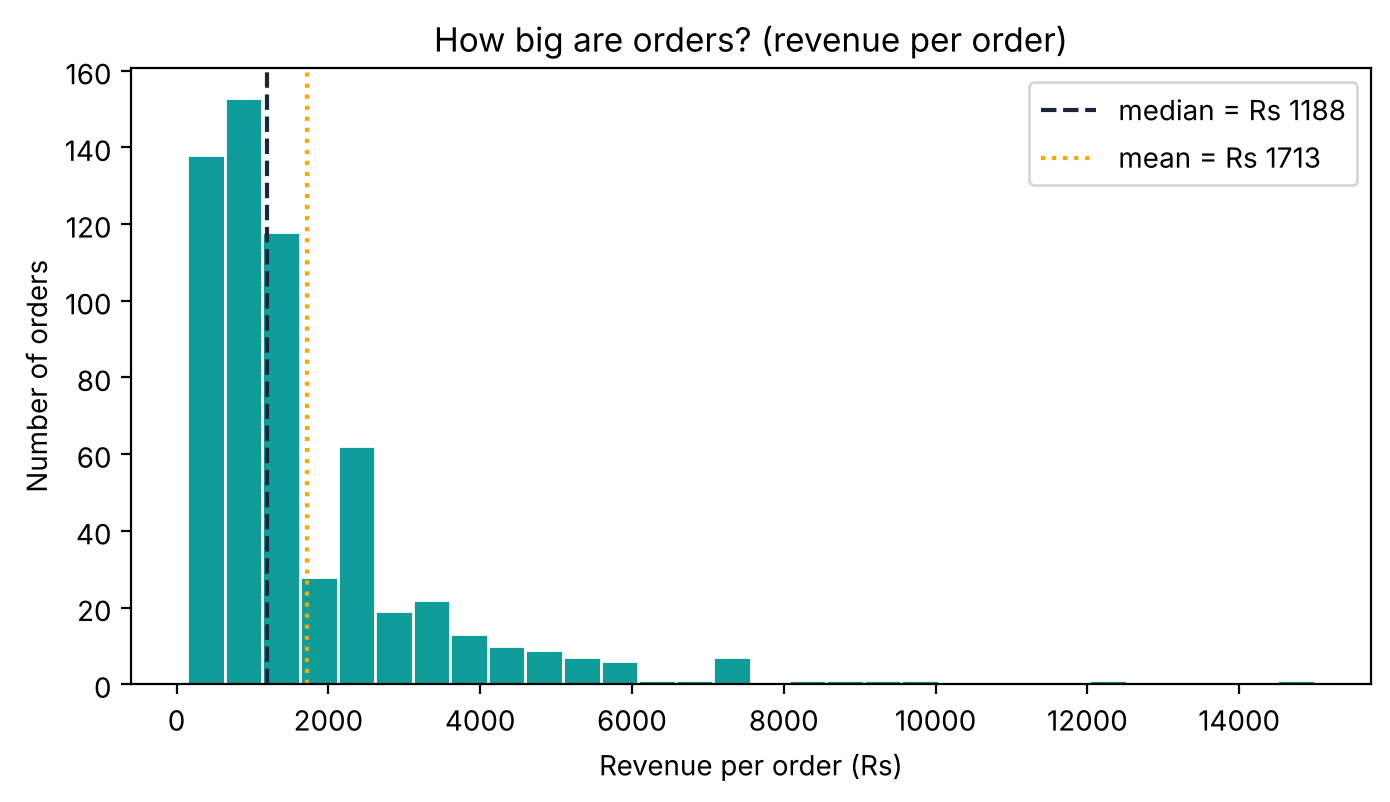

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["revenue"], bins=30, color="#0F9D9A", edgecolor="white")
ax.axvline(df["revenue"].median(), color="#1B263B", linestyle="--", label=f"median = Rs {df['revenue'].median():.0f}")
ax.axvline(df["revenue"].mean(), color="orange", linestyle=":", label=f"mean = Rs {df['revenue'].mean():.0f}")
ax.set_title("How big are orders? (revenue per order)")
ax.set_xlabel("Revenue per order (Rs)")
ax.set_ylabel("Number of orders")
ax.legend()
plt.show()

## 4. Q1 · Revenue by month (line chart)

A line chart is the right choice for change over time.

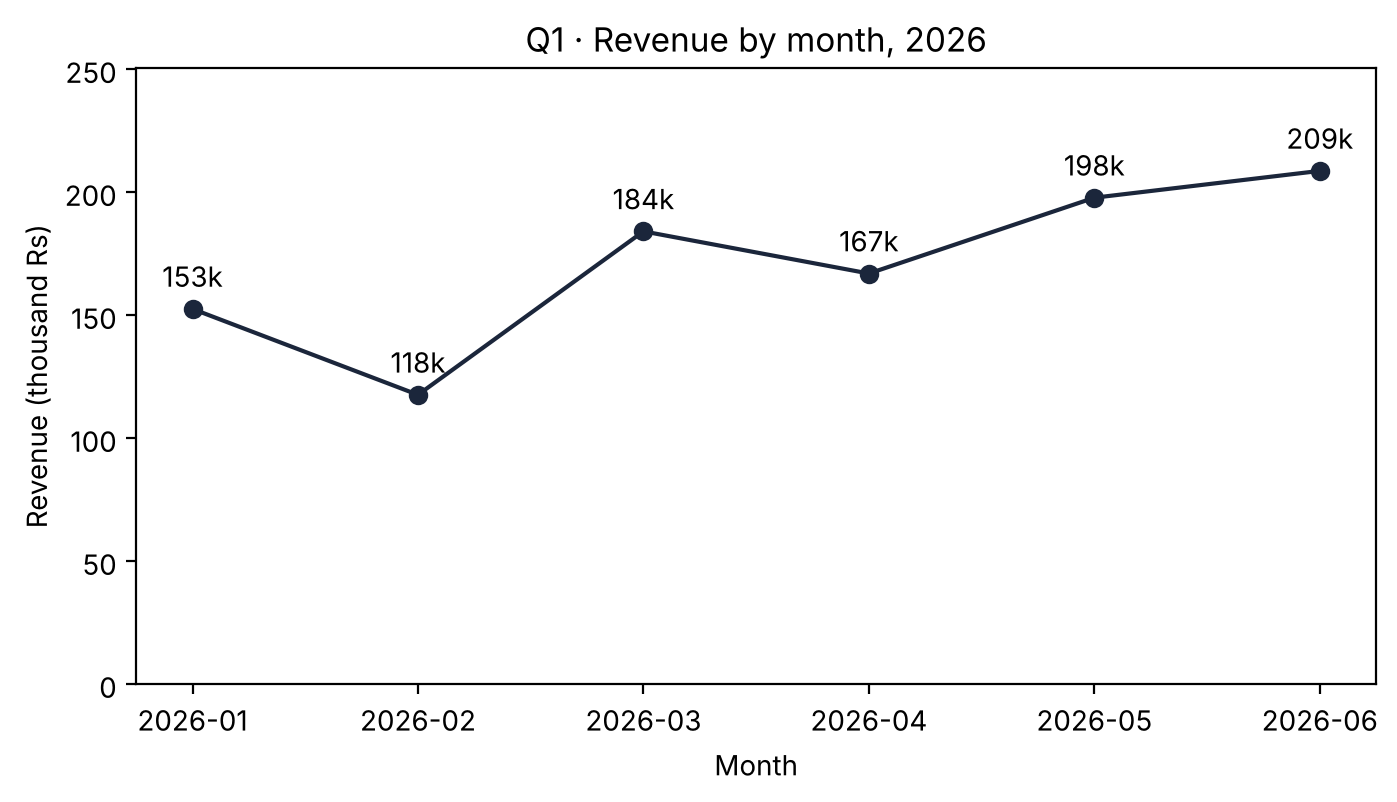

month
2026-01     NaN
2026-02   -22.9
2026-03    56.5
2026-04    -9.3
2026-05    18.5
2026-06     5.5
Name: % change vs previous month, dtype: float64


In [5]:
monthly = df.groupby("month")["revenue"].sum()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(monthly.index, monthly.values / 1000, marker="o", color="#1B263B")
for x, y in zip(monthly.index, monthly.values / 1000):
    ax.annotate(f"{y:.0f}k", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_title("Q1 · Revenue by month, 2026")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (thousand Rs)")
ax.set_ylim(0, monthly.max() / 1000 * 1.2)
plt.show()
print((monthly.pct_change() * 100).round(1).rename("% change vs previous month"))

## 5. Q2 · Categories and cities (bar charts)

Bar charts compare groups. Horizontal bars (`barh`) leave room for long labels. We sort so the biggest bar is on top.

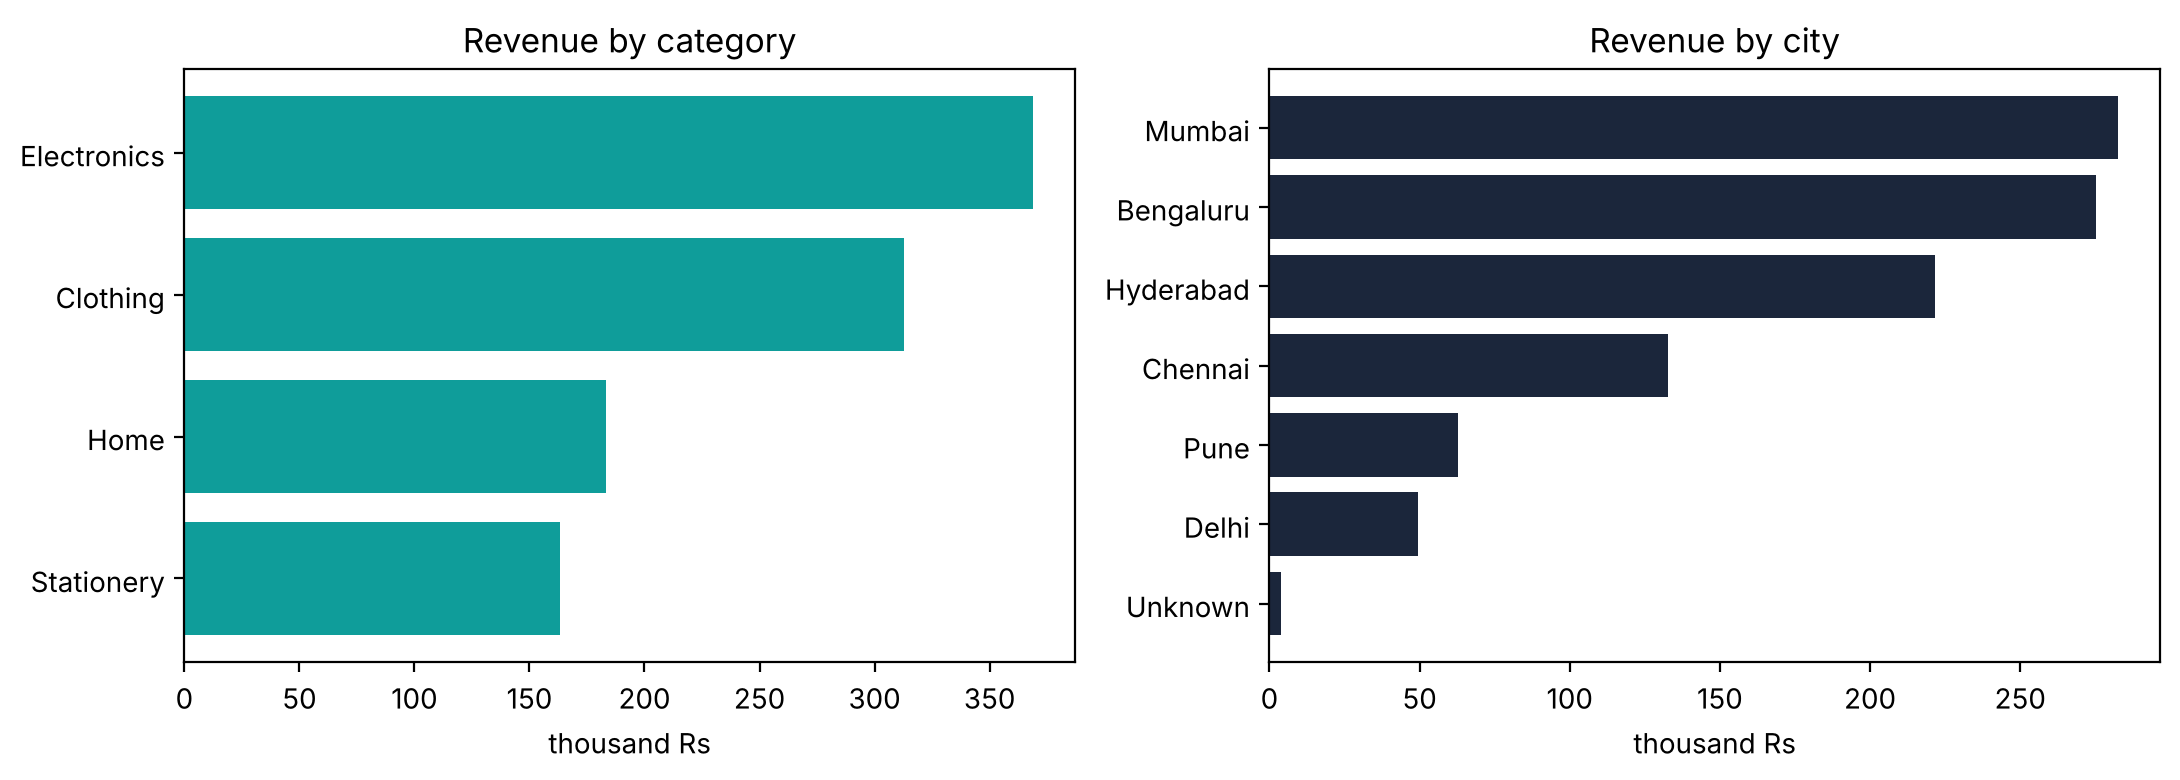

In [6]:
by_cat = df.groupby("category")["revenue"].sum().sort_values()
by_city = df.groupby("city")["revenue"].sum().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].barh(by_cat.index, by_cat.values / 1000, color="#0F9D9A")
axes[0].set_title("Revenue by category")
axes[0].set_xlabel("thousand Rs")
axes[1].barh(by_city.index, by_city.values / 1000, color="#1B263B")
axes[1].set_title("Revenue by city")
axes[1].set_xlabel("thousand Rs")
plt.tight_layout()
plt.show()

### A month × category grid

`pivot_table` plus `imshow` (draw a grid of colours) gives a simple **heatmap**: darker = more revenue.

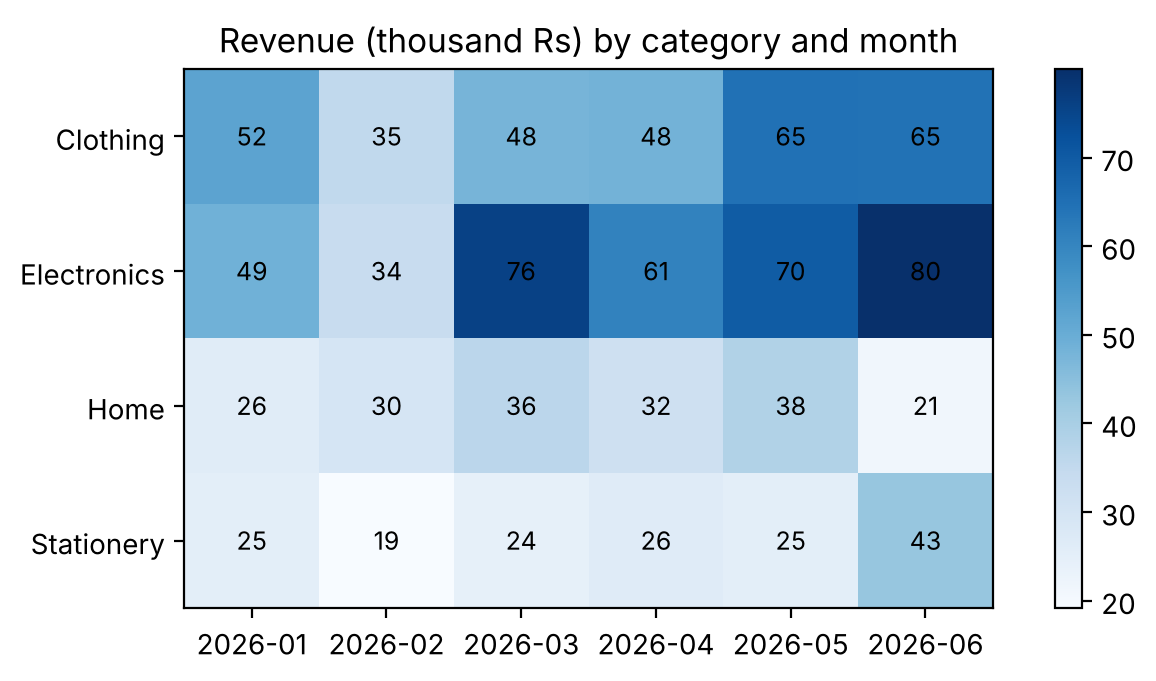

In [7]:
grid = pd.pivot_table(df, index="category", columns="month", values="revenue", aggfunc="sum") / 1000
fig, ax = plt.subplots(figsize=(8, 3.5))
im = ax.imshow(grid.values, cmap="Blues")
ax.set_xticks(range(len(grid.columns)), grid.columns)
ax.set_yticks(range(len(grid.index)), grid.index)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        ax.text(j, i, f"{grid.values[i, j]:.0f}", ha="center", va="center", fontsize=9)
ax.set_title("Revenue (thousand Rs) by category and month")
fig.colorbar(im, ax=ax)
plt.show()

## 6. Q3 · Do bigger discounts mean bigger orders?

Group by discount level and look at the average quantity. If discounts drive bigger orders, the numbers should rise from left to right.

              orders  avg_quantity  avg_revenue
discount_pct                                   
0                274          2.69      1781.43
5                129          2.76      1921.68
10               103          2.58      1472.63
15                65          2.35      1470.46
20                29          2.62      1541.35


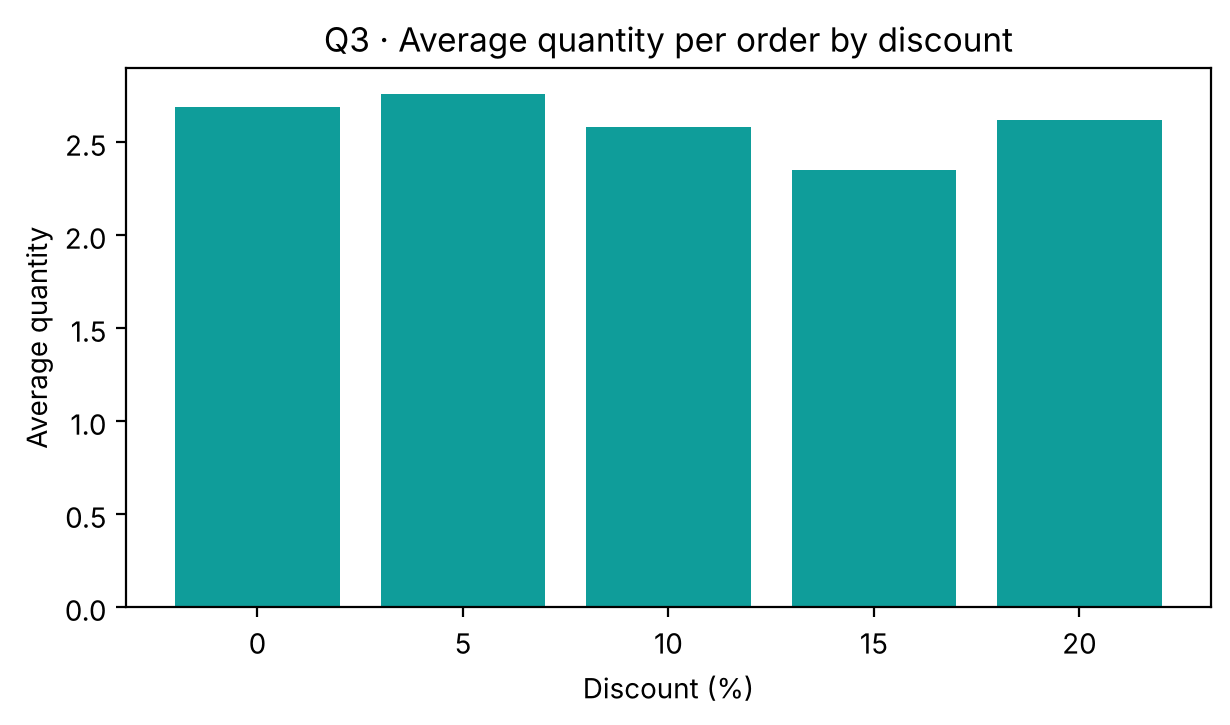

In [8]:
disc = df.groupby("discount_pct").agg(orders=("order_id", "count"),
                                      avg_quantity=("quantity", "mean"),
                                      avg_revenue=("revenue", "mean")).round(2)
print(disc)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(disc.index.astype(str), disc["avg_quantity"], color="#0F9D9A")
ax.set_title("Q3 · Average quantity per order by discount")
ax.set_xlabel("Discount (%)")
ax.set_ylabel("Average quantity")
plt.show()

In this synthetic data the discount was assigned at random, so there is no real pattern: average quantity is roughly flat.
That is a valid finding! EDA often tells you that an assumed effect is *not* there.

## 7. Q4 · Students: do study hours relate to scores?

Load the student data, fill the few missing science scores with the median, and draw a **scatter plot** (one dot per student).

attendance_pct    4
science           6
dtype: int64


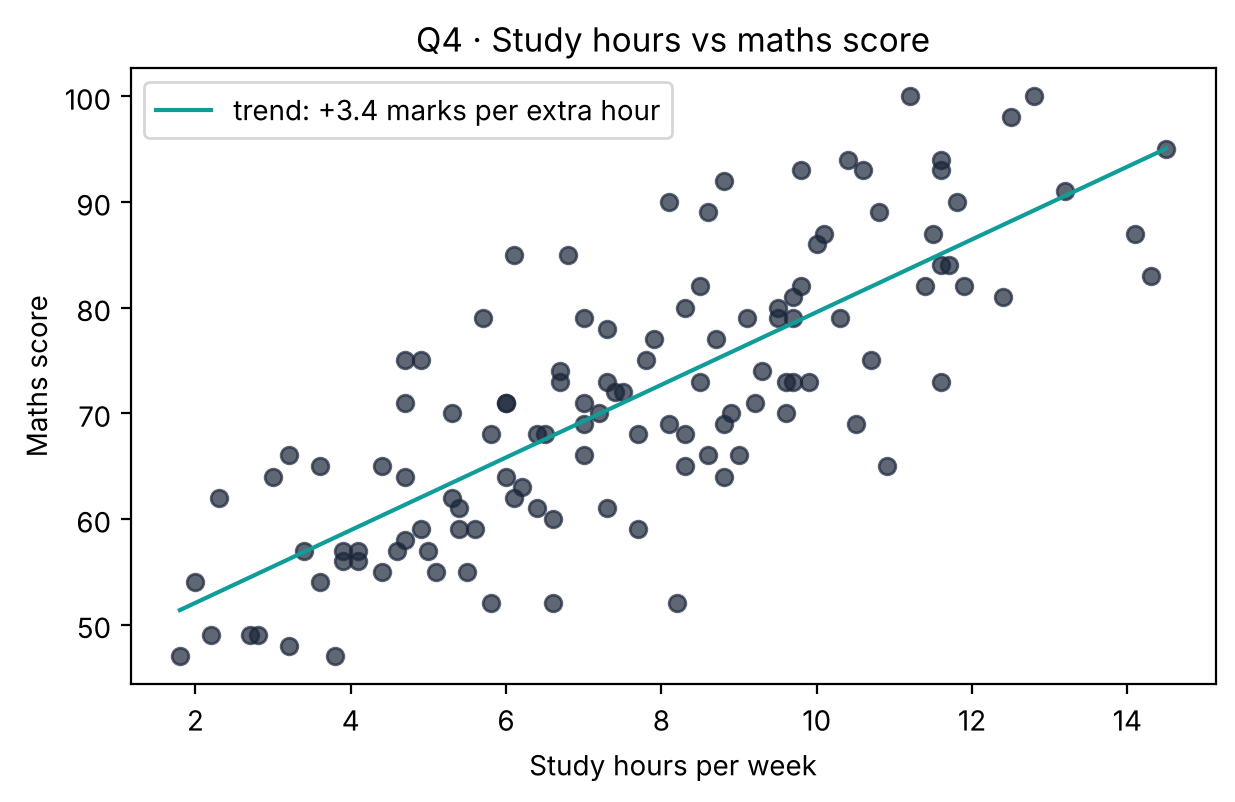

In [9]:
students = pd.read_csv(data_path("data/students.csv"))
print(students.isna().sum()[lambda s: s > 0])
students["science"] = students["science"].fillna(students["science"].median())

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(students["study_hours_per_week"], students["math"], alpha=0.7, color="#1B263B")
slope, intercept = np.polyfit(students["study_hours_per_week"], students["math"], 1)
xs = np.linspace(students["study_hours_per_week"].min(), students["study_hours_per_week"].max(), 50)
ax.plot(xs, slope * xs + intercept, color="#0F9D9A", label=f"trend: +{slope:.1f} marks per extra hour")
ax.set_title("Q4 · Study hours vs maths score")
ax.set_xlabel("Study hours per week")
ax.set_ylabel("Maths score")
ax.legend()
plt.show()

**Correlation** (−1 to +1) puts a number on "how strongly do these move together in a straight line?".
`corr(numeric_only=True)` computes it for every pair of number columns.

In [10]:
corr = students.corr(numeric_only=True).round(2)
corr

,study_hours_per_week,attendance_pct,math,science,english
study_hours_per_week,1.00,0.70,0.78,0.65,0.27
attendance_pct,0.70,1.00,0.64,0.54,0.07
math,0.78,0.64,1.00,0.52,0.23
science,0.65,0.54,0.52,1.00,0.15
english,0.27,0.07,0.23,0.15,1.00


Which section does best? Group by section and average the three subjects.

In [11]:
students["average"] = students[["math", "science", "english"]].mean(axis=1)
students["passed"] = students["average"] >= 60
section_summary = students.groupby("section").agg(
    students=("student_id", "count"),
    avg_hours=("study_hours_per_week", "mean"),
    avg_score=("average", "mean"),
    pass_rate=("passed", "mean"),
).round(2)
section_summary

,students,avg_hours,avg_score,pass_rate
section,,,,
A,40,7.68,69.61,0.88
B,44,7.32,68.32,0.86
C,36,7.87,70.14,0.89


## 8. Write the findings

Good findings are short sentences backed by numbers. The cell below builds them from the results, so they stay correct if the data changes.

In [12]:
best_month = monthly.idxmax()
findings = [
    f"Q1: Revenue was highest in {best_month} (Rs {monthly.max():,.0f}); June was {monthly.iloc[-1] / monthly.iloc[0]:.2f}x January.",
    f"Q2: {by_cat.idxmax()} is the top category (Rs {by_cat.max():,.0f}); {by_city.idxmax()} is the top city.",
    f"Q3: Average quantity ranges only from {disc['avg_quantity'].min()} to {disc['avg_quantity'].max()} across discounts - no clear effect.",
    f"Q4: Study hours and maths score have correlation {corr.loc['study_hours_per_week', 'math']}: a strong positive link (not proof of cause).",
]
for f in findings:
    print("-", f)

- Q1: Revenue was highest in 2026-06 (Rs 208,729); June was 1.37x January.
- Q2: Electronics is the top category (Rs 368,671); Mumbai is the top city.
- Q3: Average quantity ranges only from 2.35 to 2.76 across discounts - no clear effect.
- Q4: Study hours and maths score have correlation 0.78: a strong positive link (not proof of cause).


## 9. Save the results for people (Excel) and programs (CSV)

In [13]:
from pathlib import Path
out = Path("outputs")
out.mkdir(exist_ok=True)
with pd.ExcelWriter(out / "eda_summary.xlsx", engine="openpyxl") as writer:
    pd.DataFrame({"finding": findings}).to_excel(writer, sheet_name="Findings", index=False)
    monthly.round(0).to_frame("revenue").to_excel(writer, sheet_name="Monthly")
    by_cat.round(0).to_frame("revenue").to_excel(writer, sheet_name="By category")
    disc.to_excel(writer, sheet_name="Discounts")
    section_summary.to_excel(writer, sheet_name="Sections")
df.to_csv(out / "sales_enriched.csv", index=False)
print("saved:", sorted(p.name for p in out.iterdir()))

saved: ['eda_summary.xlsx', 'sales_clean.csv', 'sales_enriched.csv', 'sales_report.xlsx']


## Recap

You ran a full mini-EDA: questions → checks → merge → univariate charts → bivariate comparisons → written findings → saved outputs.
This is the same workflow you will use before every machine-learning project in Module 04.